# AI 1 · The timetable vs. real-speed problem

**Question:** do MBTA buses really run at the speeds their timetable (GTFS) implies, and if not,
are the differences **systematic and predictable**, so that a model (AI 1) can correct them?

### Why it matters
gtfs2emis estimates emissions as **distance × emission factor**, and the emission factor depends on **speed**.
It takes the speed from the timetable: distance ÷ scheduled time. If the timetable speed is wrong, the emission
factor is wrong. Emission factors rise steeply at low speeds, so errors in either direction distort the result.

### Data
- **MBTA Bus Arrival Departure Times** (Jan 2022 – Dec 2025): scheduled and actual departure times at *timepoints*
  (key stops, about 7 per trip). Scheduled times are the GTFS timetable (Phase 1.0 matched 96.6% of rows exactly).
- Five sample routes: **1, 28, 39, 66, 111**.

### Terms
| Term | Meaning |
|---|---|
| **Segment** | The road between two consecutive timepoints of one trip |
| **Last segment** | The segment that ends at the trip's final timepoint (Endpoint) |
| **Mid-route segments** | All other segments |
| **Speed factor** | scheduled time ÷ actual time = real speed ÷ timetable speed. 1 = on timetable, < 1 = slower, > 1 = faster |
| **Time-weighted factor** | total scheduled time ÷ total actual time over many segments; this is the factor of the *average speed* |
| **Delay** | actual departure − scheduled departure at a timepoint (seconds; positive = late) |

### Contents
1. One trip, step by step
2. Delay builds up along the trip
3. The last segment is padded
4. Route averages hide the problem
5. Some segments are always slow, others always fast
6. Time of day and day of week
7. Changes over the years (the 2025 shift)
8. Short segments and minute rounding
9. Can the past predict the future better than the timetable?
10. Conclusions for AI 1

## Setup
**Kaggle:** *Add Input* → the MBTA arrival/departure dataset (CSVs or yearly zips; found automatically under
`/kaggle/input`) and the GTFS feed `20240313` (used only in part 3b; without it, part 3b downloads the feed if
Internet is on, otherwise it is skipped). **Locally:** reads `data/raw/`, writes to `data/interim/timetable_vs_real/`.
Months are processed one at a time; peak memory is about 3–4 GB.

In [1]:
from pathlib import Path
import datetime, gc, io, re, time, urllib.request, zipfile
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

print("polars", pl.__version__)
if tuple(int(x) for x in pl.__version__.split(".")[:2]) < (1, 32):
    pl.enable_string_cache()  # older polars: lets categorical columns from different months be combined
pl.Config.set_tbl_rows(30); pl.Config.set_tbl_cols(20); pl.Config.set_tbl_width_chars(220); pl.Config.set_float_precision(3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False,
                     "axes.spines.right": False})

ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:
    INPUT, OUT = Path("/kaggle/input"), Path("/kaggle/working/timetable_vs_real")
else:
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists()), Path.cwd())
    INPUT, OUT = ROOT / "data" / "raw", ROOT / "data" / "interim" / "timetable_vs_real"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

ROUTES = ["01", "28", "39", "66", "111"]
ROUTE_COLORS = dict(zip(ROUTES, ["#2a6fbb", "#e07b39", "#3a9a5b", "#c0392b", "#7d5ba6"]))
EXAMPLE_DAY, EXAMPLE_ROUTE = "2024-03-13", "01"   # a normal Wednesday

FILE_RE = re.compile(r"MBTA-Bus-Arrival-Departure-Times_(\d{4}-\d{2})\.csv$")
sources = {}
for z in sorted(INPUT.rglob("*.zip")):
    try:
        for name in zipfile.ZipFile(z).namelist():
            if m := FILE_RE.search(name):
                sources[m.group(1)] = ("zip", z, name)
    except zipfile.BadZipFile:
        pass
for f in sorted(INPUT.rglob("*.csv")):
    if m := FILE_RE.search(f.name):
        sources[m.group(1)] = ("csv", f, None)
sources = dict(sorted(sources.items()))
assert sources, f"No MBTA-Bus-Arrival-Departure-Times_YYYY-MM.csv files (or zips containing them) under {INPUT}"
MONTHS = list(sources)
print(f"{len(MONTHS)} months: {MONTHS[0]} -> {MONTHS[-1]}")

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

polars 2.0.0
48 months: 2022-01 -> 2025-12


## Load the data (one pass, cached)
For each month, keep only the five routes and build three small tables:
- **segments**: one row per trip per segment, with scheduled and actual run time (seconds), hour, and whether it is
  the last segment of the trip;
- **trips**: one row per complete trip, with scheduled and actual end-to-end duration;
- **delays**: a 10% random sample of timepoint rows with their delay (actual − scheduled departure).

Plus all rows of route 1 on the example day, and all March 2024 rows of the five routes (for part 3b). Results are saved as Parquet; delete the output folder to recompute.

In [2]:
SEG_P, TRIP_P, DEV_P, DAY_P, MAR_P = (OUT / n for n in ["segments.parquet", "trips.parquet", "delays_sample.parquet",
                                                         "example_day.parquet", "rows_2024-03.parquet"])
TRIP = ["service_date", "half_trip_id"]
CAT = pl.Categorical

def open_month(month):
    kind, path, member = sources[month]
    return path if kind == "csv" else zipfile.ZipFile(path).read(member)

def seconds_of_day(col):  # "1900-01-01 06:05:00.000" (2022) or "1900-01-01T06:05:00Z" (later) -> seconds into service day
    ts = (pl.col(col).str.replace("T", " ").str.replace("Z", "").str.slice(0, 19)
          .str.strptime(pl.Datetime, "%Y-%m-%d %H:%M:%S", strict=False))
    return (ts - pl.datetime(1900, 1, 1)).dt.total_seconds().cast(pl.Int32)

def load_month(month):
    d = (pl.read_csv(open_month(month), infer_schema=False, null_values=["NA", ""],
                     columns=["service_date", "route_id", "direction_id", "half_trip_id", "stop_id", "time_point_id",
                              "time_point_order", "point_type", "standard_type", "scheduled", "actual"])
           .filter(pl.col("route_id").is_in(ROUTES) & pl.col("half_trip_id").is_not_null())
           .with_columns(sched_s=seconds_of_day("scheduled"), act_s=seconds_of_day("actual"),
                         order=pl.col("time_point_order").cast(pl.Int16))
           .drop("scheduled", "actual", "time_point_order")
           .unique(subset=TRIP + ["order"], keep="first")
           .sort(TRIP + ["order"])
           .with_columns(n_tp=pl.len().over(TRIP).cast(pl.Int16)))
    return d

if all(p.exists() for p in (SEG_P, TRIP_P, DEV_P, DAY_P, MAR_P)):
    print("Loading cached tables from", OUT)
else:
    t0, segs, trips, devs = time.time(), [], [], []
    for i, month in enumerate(MONTHS, 1):
        d = load_month(month)
        if month == EXAMPLE_DAY[:7]:
            d.filter((pl.col("service_date") == EXAMPLE_DAY) & (pl.col("route_id") == EXAMPLE_ROUTE)).write_parquet(DAY_P)
            d.write_parquet(MAR_P)
        nxt = lambda c: pl.col(c).shift(-1).over(TRIP)
        segs.append(
            d.with_columns(to_tp=nxt("time_point_id"), to_type=nxt("point_type"), se=nxt("sched_s"), ae=nxt("act_s"))
             .filter(pl.col("to_tp").is_not_null())
             .select(pl.col("route_id", "direction_id", "standard_type").cast(CAT),
                     from_tp=pl.col("time_point_id").cast(CAT), to_tp=pl.col("to_tp").cast(CAT),
                     date=pl.col("service_date").str.to_date(),
                     hour=((pl.col("sched_s") // 3600) % 24).cast(pl.Int8),
                     seg_no=pl.col("order"), is_last=(pl.col("to_type") == "Endpoint"),
                     sched=pl.col("se") - pl.col("sched_s"), act=pl.col("ae") - pl.col("act_s"))
             .filter(pl.col("act").is_not_null() & (pl.col("sched") > 0) & (pl.col("act") > 0)))
        trips.append(
            d.group_by(TRIP).agg(pl.col("route_id", "direction_id").first().cast(CAT),
                                 start_hour=((pl.col("sched_s").first() // 3600) % 24).cast(pl.Int8),
                                 complete=pl.col("act_s").is_not_null().all() & (pl.col("point_type").last() == "Endpoint"),
                                 n_tp=pl.len(),
                                 sched_total=pl.col("sched_s").last() - pl.col("sched_s").first(),
                                 act_total=pl.col("act_s").last() - pl.col("act_s").first(),
                                 sched_to_last_mid=pl.col("sched_s").get(pl.len().cast(pl.Int64) - 2) - pl.col("sched_s").first(),
                                 act_to_last_mid=pl.col("act_s").get(pl.len().cast(pl.Int64) - 2) - pl.col("act_s").first())
             .filter(pl.col("complete") & (pl.col("n_tp") >= 3))
             .with_columns(date=pl.col("service_date").str.to_date()).drop("complete", "service_date", "half_trip_id"))
        devs.append(
            d.filter(pl.col("act_s").is_not_null())
             .select(pl.col("route_id", "direction_id", "point_type", "standard_type").cast(CAT), "order", "n_tp",
                     year=pl.col("service_date").str.slice(0, 4).cast(pl.Int16),
                     delay=pl.col("act_s") - pl.col("sched_s"))
             .sample(fraction=0.10, seed=i))
        del d; gc.collect()
        print(f"\r{i}/{len(MONTHS)} {month} ({time.time() - t0:.0f}s)", end="")
    pl.concat(segs).write_parquet(SEG_P); pl.concat(trips).write_parquet(TRIP_P); pl.concat(devs).write_parquet(DEV_P)
    del segs, trips, devs; gc.collect()
    print(f"\nDone in {time.time() - t0:.0f}s")

seg_raw = pl.read_parquet(SEG_P)
seg = (seg_raw.with_columns(pl.col("sched", "act").cast(pl.Int64),  # Int64: sums over millions of segments overflow Int32
                            factor=pl.col("sched") / pl.col("act"), year=pl.col("date").dt.year().cast(pl.Int16),
                            day_type=pl.when(pl.col("date").dt.weekday() <= 5).then(pl.lit("Weekday"))
                                       .when(pl.col("date").dt.weekday() == 6).then(pl.lit("Saturday"))
                                       .otherwise(pl.lit("Sunday")).cast(CAT))
              .filter(pl.col("factor").is_between(0.2, 5)))
trips, dev = pl.read_parquet(TRIP_P), pl.read_parquet(DEV_P)
print(f"Segments with actual times: {seg_raw.height:,}; kept after sanity filter (factor 0.2–5): {seg.height:,} "
      f"({seg.height / seg_raw.height:.1%})")
print(f"Complete trips: {trips.height:,}   delay sample rows: {dev.height:,}")
del seg_raw; gc.collect()

tw = lambda: pl.col("sched").sum() / pl.col("act").sum()  # time-weighted factor
part = pl.when(pl.col("is_last")).then(pl.lit("last segment")).otherwise(pl.lit("mid-route")).alias("part")

Loading cached tables from /home/omar-hazem/projects/Grad_project/transit-emissions-platform/data/interim/timetable_vs_real


Segments with actual times: 13,375,553; kept after sanity filter (factor 0.2–5): 13,141,072 (98.2%)
Complete trips: 1,402,633   delay sample rows: 1,503,653


## 1. One trip, step by step
A route 1 trip on a normal Wednesday morning (13 March 2024). The table lists each timepoint with its scheduled and
actual departure; the chart plots the time the bus has spent since leaving the first timepoint.
If the bus followed the timetable, the two lines would lie on top of each other.

Route 1 inbound, trip 62571500, 2024-03-13
shape: (9, 9)
┌───────┬───────────────┬────────────┬───────────┬──────────┬─────────┬───────────┬─────────┬────────┐
│ order ┆ time_point_id ┆ point_type ┆ scheduled ┆ actual   ┆ delay_s ┆ sched_run ┆ act_run ┆ factor │
│ ---   ┆ ---           ┆ ---        ┆ ---       ┆ ---      ┆ ---     ┆ ---       ┆ ---     ┆ ---    │
│ i16   ┆ str           ┆ str        ┆ str       ┆ str      ┆ i32     ┆ i32       ┆ i32     ┆ f64    │
╞═══════╪═══════════════╪════════════╪═══════════╪══════════╪═════════╪═══════════╪═════════╪════════╡
│ 1     ┆ hhgat         ┆ Startpoint ┆ 08:36:00  ┆ 08:37:15 ┆ 75      ┆ null      ┆ null    ┆ null   │
│ 2     ┆ maput         ┆ Midpoint   ┆ 08:38:00  ┆ 08:39:23 ┆ 83      ┆ 120       ┆ 128     ┆ 0.938  │
│ 3     ┆ cntsq         ┆ Midpoint   ┆ 08:43:00  ┆ 08:45:31 ┆ 151     ┆ 300       ┆ 368     ┆ 0.815  │
│ 4     ┆ mit           ┆ Midpoint   ┆ 08:47:00  ┆ 08:50:26 ┆ 206     ┆ 240       ┆ 295     ┆ 0.814  │
│ 5     ┆ hynes 

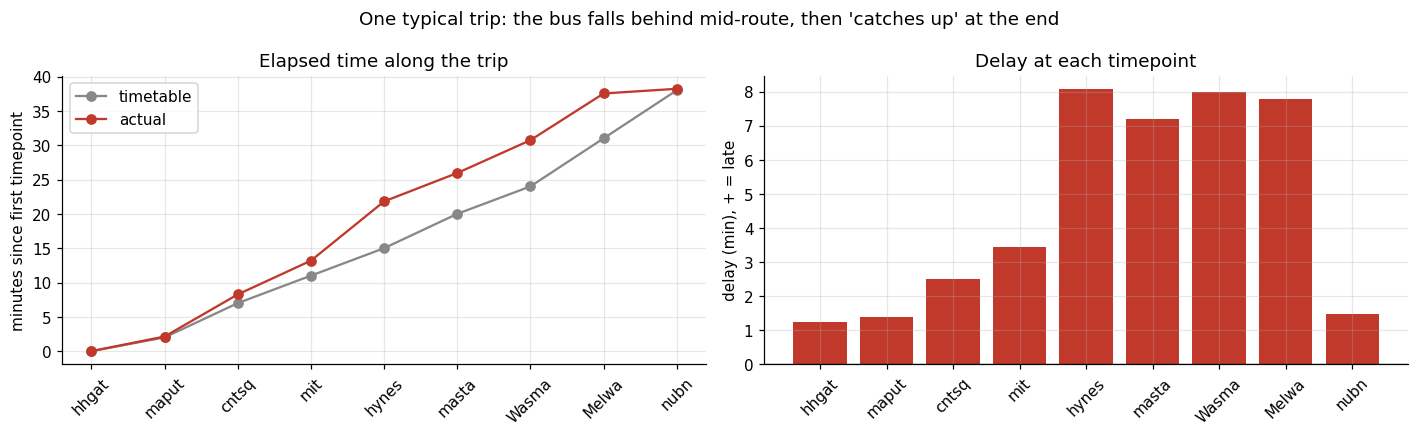

In [3]:
day = pl.read_parquet(DAY_P)
full = (day.group_by(TRIP).agg(ok=pl.col("act_s").is_not_null().all() & (pl.col("act_s").diff().min() > 0), n=pl.len(),
                               start=pl.col("sched_s").min(), dirn=pl.col("direction_id").first(),
                               mid_delay=(pl.col("act_s") - pl.col("sched_s")).get(pl.len().cast(pl.Int64) - 2))
           .filter(pl.col("ok") & pl.col("start").is_between(7 * 3600, 9 * 3600) & (pl.col("dirn") == "Inbound")))
full = full.filter(pl.col("n") == full["n"].max())
# the "typical" trip: delay at the last mid-route timepoint closest to the median of these trips
pick = full.with_columns(gap=(pl.col("mid_delay") - pl.col("mid_delay").median()).abs()).sort("gap").row(0, named=True)
trip = day.filter((pl.col("half_trip_id") == pick["half_trip_id"])).sort("order")
hhmm = lambda s: f"{s // 3600:02d}:{s % 3600 // 60:02d}:{s % 60:02d}"
t = (trip.select("order", "time_point_id", "point_type", "sched_s", "act_s")
         .with_columns(sched_run=pl.col("sched_s").diff(), act_run=pl.col("act_s").diff(),
                       delay_s=pl.col("act_s") - pl.col("sched_s"))
         .with_columns(factor=pl.col("sched_run") / pl.col("act_run")))
print(f"Route 1 inbound, trip {pick['half_trip_id']}, {EXAMPLE_DAY}")
print(t.with_columns(pl.col("sched_s").map_elements(hhmm, return_dtype=pl.String).alias("scheduled"),
                     pl.col("act_s").map_elements(hhmm, return_dtype=pl.String).alias("actual"))
       .select("order", "time_point_id", "point_type", "scheduled", "actual", "delay_s", "sched_run", "act_run", "factor"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x = t["order"].to_list()
ax[0].plot(x, (t["sched_s"] - t["sched_s"][0]) / 60, "o-", label="timetable", color="#888")
ax[0].plot(x, (t["act_s"] - t["act_s"][0]) / 60, "o-", label="actual", color="#c0392b")
ax[0].set_xticks(x, t["time_point_id"].to_list(), rotation=45)
ax[0].set_ylabel("minutes since first timepoint"); ax[0].legend(); ax[0].set_title("Elapsed time along the trip")
ax[1].bar(x, t["delay_s"] / 60, color=["#c0392b" if v > 0 else "#2a6fbb" for v in t["delay_s"].to_list()])
ax[1].axhline(0, color="k", lw=.8)
ax[1].set_xticks(x, t["time_point_id"].to_list(), rotation=45)
ax[1].set_ylabel("delay (min), + = late"); ax[1].set_title("Delay at each timepoint")
fig.suptitle("One typical trip: the bus falls behind mid-route, then 'catches up' at the end")
plt.tight_layout(); savefig(fig, "01_one_trip"); plt.show()

**How to read it:** each mid-route segment takes a bit longer than planned (factor below 1), so the delay grows.
On the last segment the timetable allows much more time than the bus needs (factor well above 1), so most of the
delay disappears by the end. The next parts check whether this is typical.

## 2. Delay builds up along the trip
Median delay at each timepoint position, for inbound trips with the most common number of timepoints on each route
(all years). The band shows the middle 50% of trips.

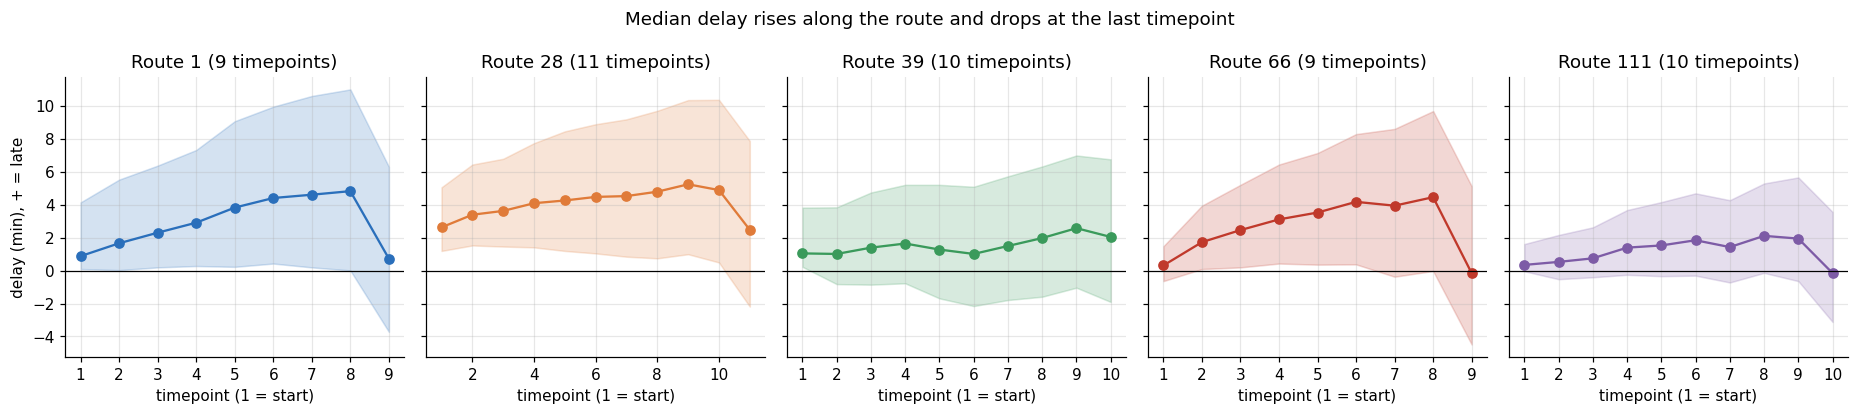

point_type,rows,median_delay_s,share_late_1min,share_early_1min
cat,u32,f64,f64,f64
"""Startpoint""",151588,64.000,0.509,0.073
"""Midpoint""",1200546,175.000,0.672,0.154
"""Endpoint""",151519,98.000,0.538,0.331


In [4]:
fig, axes = plt.subplots(1, len(ROUTES), figsize=(17, 3.8), sharey=True)
for ax, r in zip(axes, ROUTES):
    dr = dev.filter((pl.col("route_id") == r) & (pl.col("direction_id") == "Inbound"))
    n_common = dr.group_by("n_tp").len().sort("len", descending=True)["n_tp"][0]
    prof = (dr.filter(pl.col("n_tp") == n_common).group_by("order")
              .agg(p25=pl.col("delay").quantile(.25), p50=pl.col("delay").median(), p75=pl.col("delay").quantile(.75))
              .sort("order"))
    ax.fill_between(prof["order"], prof["p25"] / 60, prof["p75"] / 60, alpha=.2, color=ROUTE_COLORS[r])
    ax.plot(prof["order"], prof["p50"] / 60, "o-", color=ROUTE_COLORS[r])
    ax.axhline(0, color="k", lw=.8)
    ax.set_title(f"Route {r.lstrip('0')} ({n_common} timepoints)"); ax.set_xlabel("timepoint (1 = start)")
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
axes[0].set_ylabel("delay (min), + = late")
fig.suptitle("Median delay rises along the route and drops at the last timepoint")
plt.tight_layout(); savefig(fig, "02_delay_profile"); plt.show()

delay_tab = (dev.group_by("point_type").agg(rows=pl.len(), median_delay_s=pl.col("delay").median(),
                                            share_late_1min=(pl.col("delay") > 60).mean(),
                                            share_early_1min=(pl.col("delay") < -60).mean())
                .sort("point_type", descending=True))
delay_tab

## 3. The last segment is padded
Distribution of the speed factor for the last segment of each trip vs. all other segments (all routes, all years).

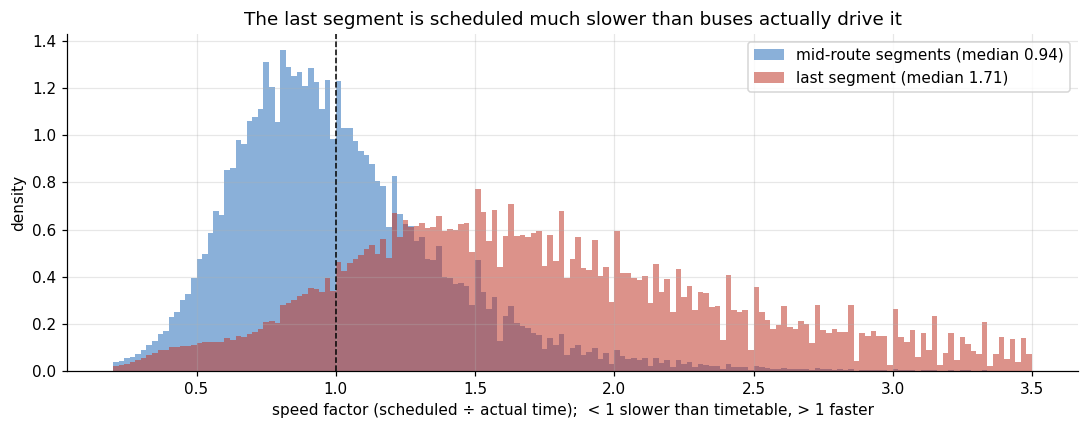

part,segments,share_of_sched_time,median_factor,time_weighted_factor,mean_sched_s,mean_act_s
str,u32,f64,f64,f64,f64,f64
"""mid-route""",11845264,0.848,0.945,0.921,224.049,243.215
"""last segment""",1295808,0.152,1.714,1.523,365.906,240.215


In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
bins = [i / 50 for i in range(10, 176)]
for flag, label, color in [(False, "mid-route segments", "#2a6fbb"), (True, "last segment", "#c0392b")]:
    v = seg.filter(pl.col("is_last") == flag)["factor"].to_numpy()
    ax.hist(v, bins=bins, density=True, alpha=.55, label=f"{label} (median {pl.Series(v).median():.2f})", color=color)
ax.axvline(1, color="k", lw=1, ls="--")
ax.set_xlabel("speed factor (scheduled ÷ actual time);  < 1 slower than timetable, > 1 faster")
ax.set_ylabel("density"); ax.legend()
ax.set_title("The last segment is scheduled much slower than buses actually drive it")
plt.tight_layout(); savefig(fig, "03_last_vs_mid_hist"); plt.show()

last_tab = (seg.with_columns(part).group_by("part")
               .agg(segments=pl.len(), share_of_sched_time=pl.col("sched").sum(),
                    median_factor=pl.col("factor").median(), time_weighted_factor=tw(),
                    mean_sched_s=pl.col("sched").mean(), mean_act_s=pl.col("act").mean())
               .with_columns(share_of_sched_time=pl.col("share_of_sched_time") / pl.col("share_of_sched_time").sum())
               .sort("part", descending=True))
last_tab

**Why:** transit agencies add *recovery time* (padding) before the end of a trip so that a late bus still finishes
on time and the next trip can leave on schedule. The timetable therefore implies a very slow last segment that buses
do not actually drive. GTFS contains the same padded times, so gtfs2emis sees the same slow speed there.

### 3b. Distances confirm the padding
With stop locations from the GTFS feed valid in March 2024, times become **speeds**. Distance here is the straight
line between the two timepoint stops — shorter than the road, so every speed is an underestimate, but timetable and
actual speeds use the same distance, so they compare fairly. March 2024, five routes.
If the last segment is padded, the timetable should imply an implausibly slow speed there.

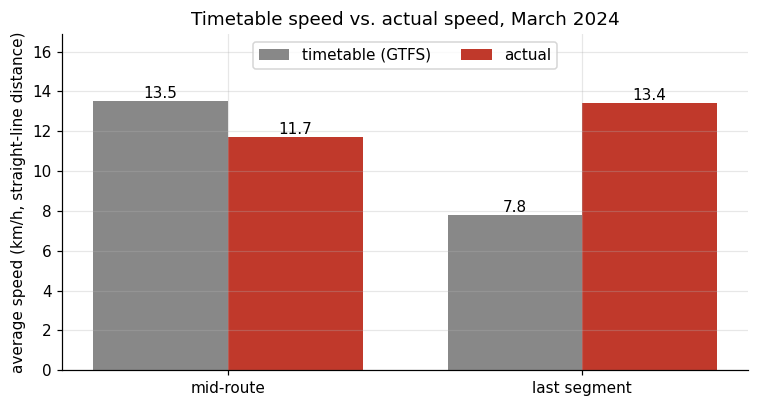

shape: (2, 5)
┌──────────────┬──────────┬───────────┬───────────────┬────────────┐
│ part         ┆ segments ┆ median_km ┆ timetable_kmh ┆ actual_kmh │
│ ---          ┆ ---      ┆ ---       ┆ ---           ┆ ---        │
│ str          ┆ u32      ┆ f64       ┆ f64           ┆ f64        │
╞══════════════╪══════════╪═══════════╪═══════════════╪════════════╡
│ mid-route    ┆ 216248   ┆ 0.811     ┆ 13.503        ┆ 11.697     │
│ last segment ┆ 31008    ┆ 0.958     ┆ 7.807         ┆ 13.437     │
└──────────────┴──────────┴───────────┴───────────────┴────────────┘
Last segment of each route and direction (medians):
shape: (10, 10)
┌──────────┬──────────────┬───────────────┬───────┬───────┬───────┬───────────┬─────────┬───────────────┬────────────┐
│ route_id ┆ direction_id ┆ time_point_id ┆ to_tp ┆ trips ┆ km    ┆ sched_min ┆ act_min ┆ timetable_kmh ┆ actual_kmh │
│ ---      ┆ ---          ┆ ---           ┆ ---   ┆ ---   ┆ ---   ┆ ---       ┆ ---     ┆ ---           ┆ ---        │
│ str    

In [6]:
def find_gtfs(feed="20240313"):
    """GTFS feed from the inputs (zip, or a folder if Kaggle unzipped it), else try to download it."""
    for z in INPUT.rglob(f"{feed}.zip"):
        return zipfile.ZipFile(z)
    for st in INPUT.rglob("stops.txt"):
        if feed in str(st.parent):
            return st.parent
    target = OUT / f"{feed}.zip"
    if not target.exists():
        urllib.request.urlretrieve(f"https://cdn.mbtace.com/archive/{feed}.zip", target)
    return zipfile.ZipFile(target)

try:
    FEED = find_gtfs()
except Exception as e:
    FEED = None
    print(f"GTFS feed not available ({e}); add it as an input or turn Internet on. Skipping part 3b.")

if FEED is not None:
    raw = FEED.read("stops.txt") if isinstance(FEED, zipfile.ZipFile) else (FEED / "stops.txt").read_bytes()
    stops = pl.read_csv(io.BytesIO(raw), infer_schema=False).select(
        "stop_id", lat=pl.col("stop_lat").cast(pl.Float64), lon=pl.col("stop_lon").cast(pl.Float64))
    rad = lambda c: pl.col(c) * (3.141592653589793 / 180)
    nx = lambda c: pl.col(c).shift(-1).over(TRIP)
    mar = (pl.read_parquet(MAR_P).join(stops, on="stop_id", how="left")
             .with_columns(lat2=nx("lat"), lon2=nx("lon"), se=nx("sched_s"), ae=nx("act_s"), to_type=nx("point_type"),
                           to_tp=nx("time_point_id"))
             .filter(pl.col("lat2").is_not_null() & pl.col("act_s").is_not_null() & pl.col("ae").is_not_null())
             .with_columns(km=2 * 6371 * ((((rad("lat2") - rad("lat")) / 2).sin() ** 2
                                           + rad("lat").cos() * rad("lat2").cos() * (((rad("lon2") - rad("lon")) / 2).sin() ** 2))
                                          .sqrt().arcsin()),
                           sched=(pl.col("se") - pl.col("sched_s")).cast(pl.Int64),
                           act=(pl.col("ae") - pl.col("act_s")).cast(pl.Int64),
                           part=pl.when(pl.col("to_type") == "Endpoint").then(pl.lit("last segment")).otherwise(pl.lit("mid-route")))
             .filter((pl.col("sched") > 0) & (pl.col("act") > 0) & (pl.col("km") > 0.05)))
    kmh = lambda t: pl.col("km").sum() / (pl.col(t).sum() / 3600)
    speed_tab = (mar.group_by("part").agg(segments=pl.len(), median_km=pl.col("km").median(),
                                          timetable_kmh=kmh("sched"), actual_kmh=kmh("act"))
                    .sort("part", descending=True))
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for k, (col, label, color) in enumerate([("timetable_kmh", "timetable (GTFS)", "#888"), ("actual_kmh", "actual", "#c0392b")]):
        bars = ax.bar([i + (k - .5) * .38 for i in range(speed_tab.height)], speed_tab[col], .38, label=label, color=color)
        ax.bar_label(bars, fmt="%.1f")
    ax.set_xticks(range(speed_tab.height), speed_tab["part"].to_list())
    ax.set_ylim(0, speed_tab.select(pl.max_horizontal("timetable_kmh", "actual_kmh")).max().item() * 1.25)
    ax.set_ylabel("average speed (km/h, straight-line distance)"); ax.legend(loc="upper center", ncol=2)
    ax.set_title("Timetable speed vs. actual speed, March 2024")
    plt.tight_layout(); savefig(fig, "03b_speeds_kmh"); plt.show()
    print(speed_tab)
    last_routes = (mar.filter(pl.col("part") == "last segment")
                      .group_by("route_id", "direction_id", "time_point_id", "to_tp")
                      .agg(trips=pl.len(), km=pl.col("km").median(), sched_min=pl.col("sched").median() / 60,
                           act_min=pl.col("act").median() / 60)
                      .filter(pl.col("trips") >= 300)
                      .with_columns(timetable_kmh=pl.col("km") / (pl.col("sched_min") / 60),
                                    actual_kmh=pl.col("km") / (pl.col("act_min") / 60))
                      .sort("route_id", "direction_id"))
    print("Last segment of each route and direction (medians):")
    display(last_routes) if "display" in globals() else print(last_routes)

Mid-route, buses drive **slower** than the timetable implies; on the last segment the timetable implies a speed
close to walking pace on some routes, which no bus drives — that time is padding.

## 4. Route averages hide the problem
Mid-route slowness and last-segment padding cancel out when all segments are averaged together.

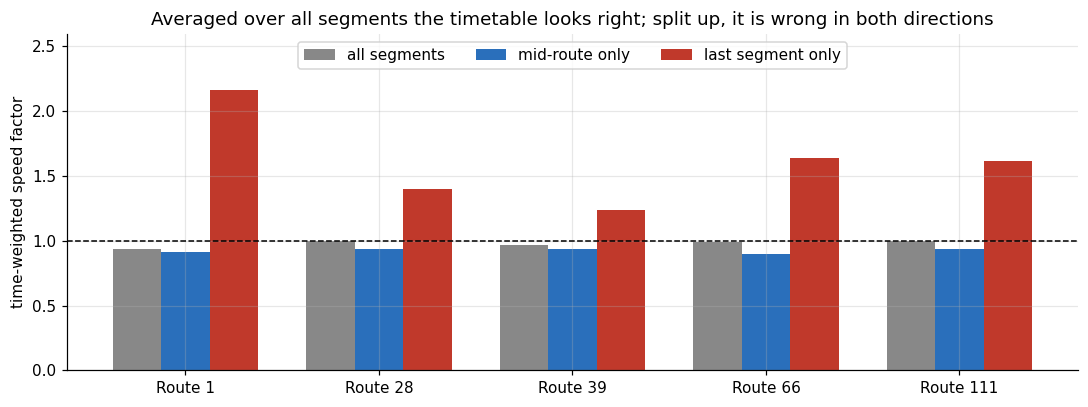

route_id,all_median,all_time_weighted,mid_time_weighted,last_time_weighted
cat,f64,f64,f64,f64
"""01""",0.946,0.936,0.910,2.162
"""28""",0.984,0.997,0.934,1.399
"""39""",1.000,0.964,0.934,1.236
"""66""",0.968,0.989,0.894,1.639
"""111""",1.000,1.000,0.939,1.614


In [7]:
avg_tab = (seg.group_by("route_id")
              .agg(all_median=pl.col("factor").median(), all_time_weighted=tw(),
                   mid_time_weighted=(pl.col("sched").filter(~pl.col("is_last")).sum()
                                      / pl.col("act").filter(~pl.col("is_last")).sum()),
                   last_time_weighted=(pl.col("sched").filter(pl.col("is_last")).sum()
                                       / pl.col("act").filter(pl.col("is_last")).sum()))
              .with_columns(o=pl.col("route_id").cast(pl.String).replace_strict(ROUTES, list(range(len(ROUTES)))))
              .sort("o").drop("o"))
fig, ax = plt.subplots(figsize=(10, 3.8))
w = .25
xs = range(len(ROUTES))
for k, (col, label, color) in enumerate([("all_time_weighted", "all segments", "#888"),
                                         ("mid_time_weighted", "mid-route only", "#2a6fbb"),
                                         ("last_time_weighted", "last segment only", "#c0392b")]):
    ax.bar([i + (k - 1) * w for i in xs], avg_tab[col], w, label=label, color=color)
ax.axhline(1, color="k", lw=1, ls="--")
ax.set_xticks(list(xs), [f"Route {r.lstrip('0')}" for r in avg_tab["route_id"].cast(pl.String)])
ax.set_ylim(0, avg_tab["last_time_weighted"].max() * 1.2)
ax.set_ylabel("time-weighted speed factor"); ax.legend(ncol=3, loc="upper center")
ax.set_title("Averaged over all segments the timetable looks right; split up, it is wrong in both directions")
plt.tight_layout(); savefig(fig, "04_route_average_split"); plt.show()
avg_tab

## 5. Some segments are always slow, others always fast
Each bar is one segment of route 1 inbound (weekdays, 2024): its median speed factor, with the 10th–90th percentile
of trips as a whisker. If differences were random, every bar would sit near 1.

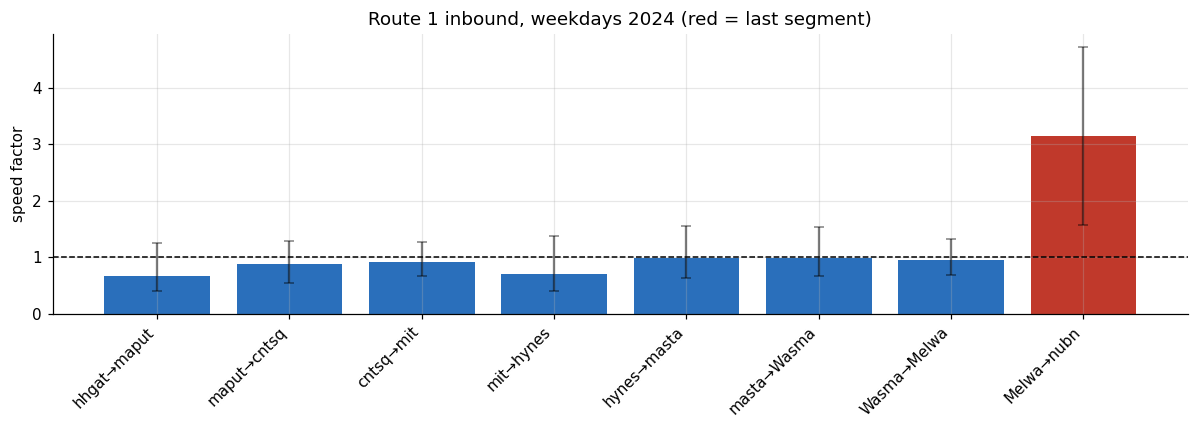

All 5 routes, weekdays 2024 — share of segments whose MEDIAN factor is ...


part,segments,consistently_slower_10pct,near_timetable,consistently_faster_10pct
str,u32,f64,f64,f64
"""mid-route""",80,0.425,0.450,0.125
"""last segment""",12,0.000,0.000,1.000


In [8]:
r1 = seg.filter((pl.col("route_id") == "01") & (pl.col("direction_id") == "Inbound")
                & (pl.col("year") == 2024) & (pl.col("day_type") == "Weekday"))
pairs = (r1.group_by("from_tp", "to_tp").agg(n=pl.len(), seg_no=pl.col("seg_no").median(),
                                             is_last=pl.col("is_last").mean() > .5,
                                             p10=pl.col("factor").quantile(.1), p50=pl.col("factor").median(),
                                             p90=pl.col("factor").quantile(.9))
           .filter(pl.col("n") >= 500).sort("seg_no"))
fig, ax = plt.subplots(figsize=(11, 4))
labels = [f"{a}→{b}" for a, b in zip(pairs["from_tp"].cast(pl.String), pairs["to_tp"].cast(pl.String))]
colors = ["#c0392b" if l else "#2a6fbb" for l in pairs["is_last"].to_list()]
ax.bar(range(pairs.height), pairs["p50"], color=colors)
ax.errorbar(range(pairs.height), pairs["p50"], yerr=[pairs["p50"] - pairs["p10"], pairs["p90"] - pairs["p50"]],
            fmt="none", ecolor="k", alpha=.5, capsize=3)
ax.axhline(1, color="k", lw=1, ls="--")
ax.set_xticks(range(pairs.height), labels, rotation=45, ha="right")
ax.set_ylabel("speed factor"); ax.set_title("Route 1 inbound, weekdays 2024 (red = last segment)")
plt.tight_layout(); savefig(fig, "05_route1_segments"); plt.show()

per_seg = (seg.filter((pl.col("year") == 2024) & (pl.col("day_type") == "Weekday"))
              .group_by("route_id", "direction_id", "from_tp", "to_tp")
              .agg(n=pl.len(), med=pl.col("factor").median(), is_last=pl.col("is_last").mean() > .5)
              .filter(pl.col("n") >= 200))
seg_share = (per_seg.with_columns(part=pl.when(pl.col("is_last")).then(pl.lit("last segment")).otherwise(pl.lit("mid-route")))
                    .group_by("part").agg(segments=pl.len(),
                                          consistently_slower_10pct=(pl.col("med") < .9).mean(),
                                          near_timetable=pl.col("med").is_between(.9, 1.1).mean(),
                                          consistently_faster_10pct=(pl.col("med") > 1.1).mean())
                    .sort("part", descending=True))
print("All 5 routes, weekdays 2024 — share of segments whose MEDIAN factor is ...")
seg_share

## 6. Time of day and day of week
Time-weighted factor of **mid-route segments** by scheduled hour, 2024 only (one timetable regime, see part 7).

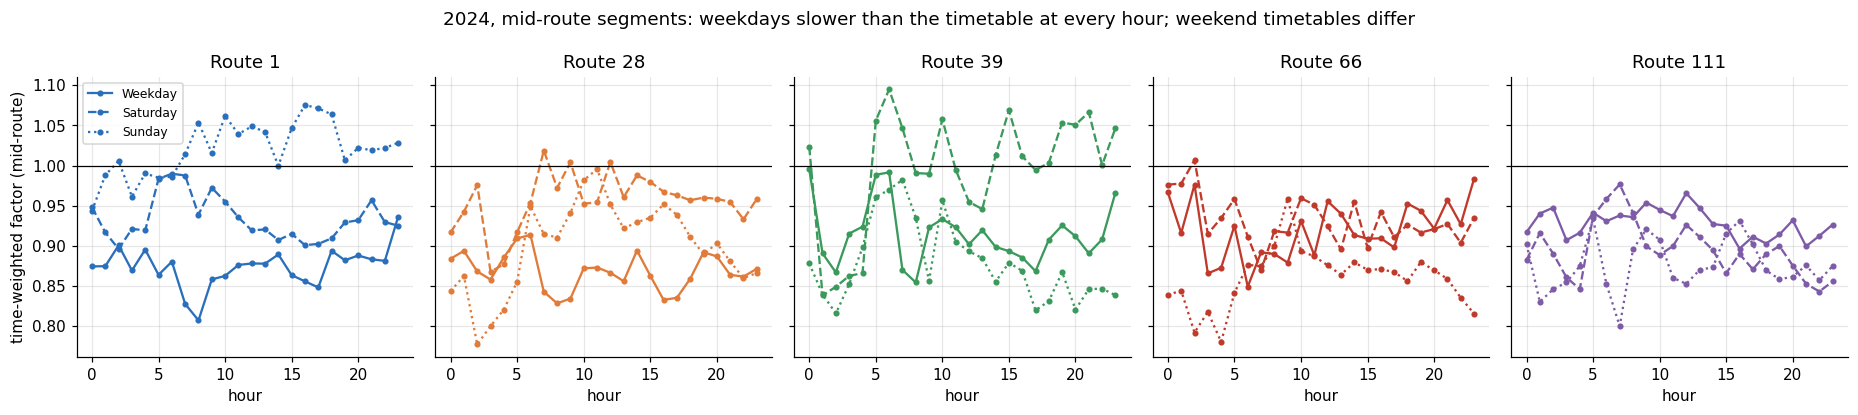

Weekday 2024, mid-route, time-weighted factor by period


route_id,1 early 5–6,2 AM peak 7–9,3 midday 10–14,4 PM peak 15–18,5 evening/night
cat,f64,f64,f64,f64,f64
"""01""",0.871,0.831,0.878,0.864,0.889
"""111""",0.937,0.942,0.945,0.909,0.920
"""28""",0.912,0.835,0.872,0.847,0.877
"""39""",0.990,0.879,0.914,0.888,0.922
"""66""",0.882,0.887,0.925,0.917,0.939


In [9]:
hourly = (seg.filter((pl.col("year") == 2024) & ~pl.col("is_last"))
             .group_by("route_id", "day_type", "hour").agg(f=tw(), n=pl.len()).filter(pl.col("n") >= 300)
             .sort("hour"))
fig, axes = plt.subplots(1, len(ROUTES), figsize=(17, 3.8), sharey=True)
for ax, r in zip(axes, ROUTES):
    for dt, ls in [("Weekday", "-"), ("Saturday", "--"), ("Sunday", ":")]:
        h = hourly.filter((pl.col("route_id") == r) & (pl.col("day_type") == dt))
        ax.plot(h["hour"], h["f"], ls, marker=".", label=dt, color=ROUTE_COLORS[r])
    ax.axhline(1, color="k", lw=.8)
    ax.set_title(f"Route {r.lstrip('0')}"); ax.set_xlabel("hour")
axes[0].set_ylabel("time-weighted factor (mid-route)"); axes[0].legend(fontsize=8)
fig.suptitle("2024, mid-route segments: weekdays slower than the timetable at every hour; weekend timetables differ")
plt.tight_layout(); savefig(fig, "06_hour_daytype"); plt.show()

period = (pl.when(pl.col("hour").is_between(5, 6)).then(pl.lit("1 early 5–6"))
            .when(pl.col("hour").is_between(7, 9)).then(pl.lit("2 AM peak 7–9"))
            .when(pl.col("hour").is_between(10, 14)).then(pl.lit("3 midday 10–14"))
            .when(pl.col("hour").is_between(15, 18)).then(pl.lit("4 PM peak 15–18"))
            .otherwise(pl.lit("5 evening/night")))
period_tab = (seg.filter((pl.col("year") == 2024) & ~pl.col("is_last") & (pl.col("day_type") == "Weekday"))
                 .with_columns(p=period).group_by("route_id", "p").agg(f=tw()).sort("p")
                 .pivot(on="p", index="route_id", values="f").sort("route_id"))
print("Weekday 2024, mid-route, time-weighted factor by period")
period_tab

## 7. Changes over the years: timetable revisions
Left: monthly time-weighted factor of mid-route segments. Right: for weekday trips on routes 1 and 66, the average
**scheduled** (dashed) and **actual** (solid) time from the first to the last mid-route timepoint (padding excluded).
When the factor jumps because the **scheduled** time jumps while the actual time moves little, MBTA revised the
timetable — the buses did not suddenly get faster. The dotted line marks January 2025, when MBTA also changed how
it records this dataset.

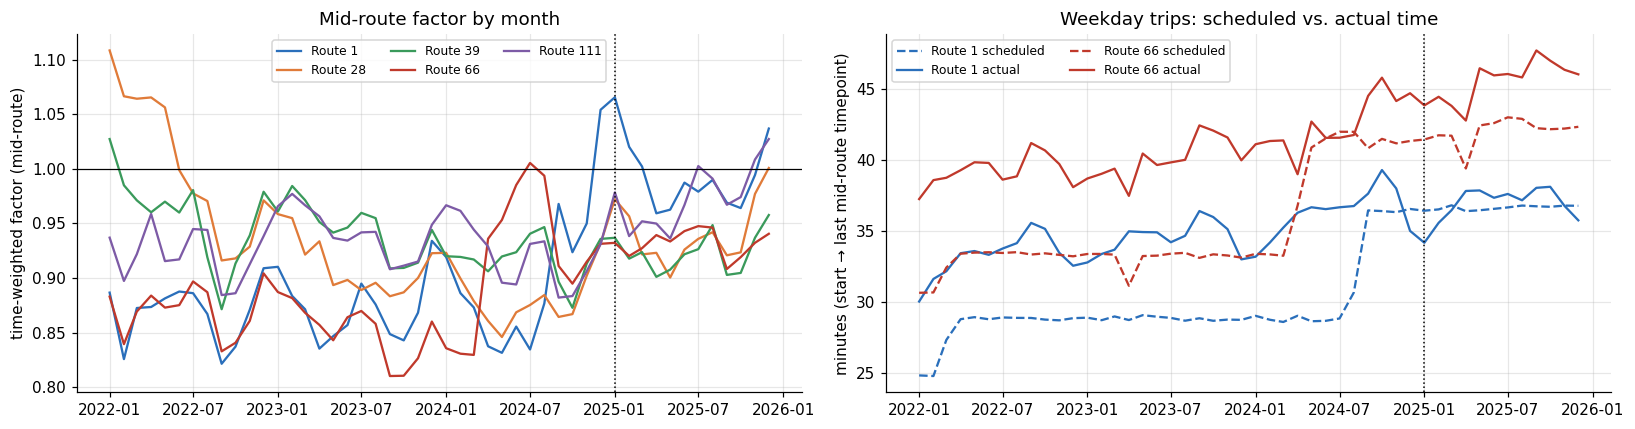

Weekday mid-route time-weighted factor by year
shape: (5, 5)
┌──────────┬───────┬───────┬───────┬───────┐
│ route_id ┆ 2022  ┆ 2023  ┆ 2024  ┆ 2025  │
│ ---      ┆ ---   ┆ ---   ┆ ---   ┆ ---   │
│ cat      ┆ f64   ┆ f64   ┆ f64   ┆ f64   │
╞══════════╪═══════╪═══════╪═══════╪═══════╡
│ 01       ┆ 0.849 ┆ 0.842 ┆ 0.876 ┆ 1.001 │
│ 111      ┆ 0.913 ┆ 0.947 ┆ 0.927 ┆ 0.979 │
│ 28       ┆ 0.994 ┆ 0.889 ┆ 0.867 ┆ 0.945 │
│ 39       ┆ 0.956 ┆ 0.936 ┆ 0.913 ┆ 0.919 │
│ 66       ┆ 0.847 ┆ 0.834 ┆ 0.923 ┆ 0.935 │
└──────────┴───────┴───────┴───────┴───────┘
Timetable revisions: months where the average scheduled trip time changed by more than 1.5 min


route_id,month,scheduled_min,change_min,actual_min
cat,str,f64,f64,f64
"""01""","""2022-03""",27.301,2.545,32.149
"""01""","""2024-08""",30.652,1.835,36.749
"""01""","""2024-09""",36.441,5.789,37.626
"""28""","""2022-07""",31.969,-2.153,33.476
"""28""","""2024-09""",34.224,1.965,40.554
"""66""","""2022-03""",32.409,1.755,38.744
"""66""","""2023-04""",31.127,-2.193,37.468
"""66""","""2023-05""",33.223,2.096,40.455
"""66""","""2024-04""",36.779,3.535,38.994


In [10]:
monthly = (seg.filter(~pl.col("is_last")).with_columns(m=pl.col("date").dt.truncate("1mo"))
              .group_by("route_id", "m").agg(f=tw()).sort("m"))
tr_m = (trips.filter(pl.col("date").dt.weekday() <= 5)
             .with_columns(m=pl.col("date").dt.truncate("1mo"))
             .group_by("route_id", "m").agg(sched=pl.col("sched_to_last_mid").mean() / 60,
                                            act=pl.col("act_to_last_mid").mean() / 60)
             .sort("route_id", "m"))
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for r in ROUTES:
    mm = monthly.filter(pl.col("route_id") == r)
    ax[0].plot(mm["m"], mm["f"], label=f"Route {r.lstrip('0')}", color=ROUTE_COLORS[r])
ax[0].axhline(1, color="k", lw=.8); ax[0].set_ylabel("time-weighted factor (mid-route)")
ax[0].set_title("Mid-route factor by month"); ax[0].legend(ncol=3, fontsize=8)
for r in ["01", "66"]:
    tt = tr_m.filter(pl.col("route_id") == r)
    ax[1].plot(tt["m"], tt["sched"], "--", color=ROUTE_COLORS[r], label=f"Route {r.lstrip('0')} scheduled")
    ax[1].plot(tt["m"], tt["act"], "-", color=ROUTE_COLORS[r], label=f"Route {r.lstrip('0')} actual")
ax[1].set_ylabel("minutes (start → last mid-route timepoint)")
ax[1].set_title("Weekday trips: scheduled vs. actual time"); ax[1].legend(ncol=2, fontsize=8)
for a in ax:
    a.axvline(datetime.date(2025, 1, 1), color="k", ls=":", lw=1)  # January 2025
plt.tight_layout(); savefig(fig, "07_years"); plt.show()

yearly = (seg.filter(~pl.col("is_last") & (pl.col("day_type") == "Weekday"))
             .group_by("route_id", "year").agg(f=tw()).sort("year")
             .pivot(on="year", index="route_id", values="f").sort("route_id"))
print("Weekday mid-route time-weighted factor by year")
print(yearly)
revisions = (tr_m.with_columns(change_min=pl.col("sched").diff().over("route_id"))
                 .filter(pl.col("change_min").abs() > 1.5)
                 .select("route_id", month=pl.col("m").dt.strftime("%Y-%m"), scheduled_min="sched", change_min="change_min",
                         actual_min="act"))
print("Timetable revisions: months where the average scheduled trip time changed by more than 1.5 min")
revisions

In [11]:
trip_year = (trips.filter(pl.col("date").dt.weekday() <= 5).with_columns(year=pl.col("date").dt.year())
                  .group_by("route_id", "year")
                  .agg(sched_min=pl.col("sched_to_last_mid").mean() / 60, act_min=pl.col("act_to_last_mid").mean() / 60)
                  .sort("route_id", "year"))
print("Weekday trips, start → last mid-route timepoint: mean scheduled vs. actual minutes")
trip_year

Weekday trips, start → last mid-route timepoint: mean scheduled vs. actual minutes


route_id,year,sched_min,act_min
cat,i32,f64,f64
"""01""",2022,27.978,33.181
"""01""",2023,28.814,34.458
"""01""",2024,31.460,36.274
"""01""",2025,36.632,36.888
"""111""",2022,20.745,23.270
"""111""",2023,22.114,23.796
"""111""",2024,22.065,24.192
"""111""",2025,22.881,24.660
"""28""",2022,33.513,33.976


## 8. Short segments and minute rounding
Scheduled times are always whole minutes, actual times have seconds. On a 1-minute segment the true planned time
could be anything from about 30 to 90 seconds, so its factor is unreliable. Mid-route segments, 2024.

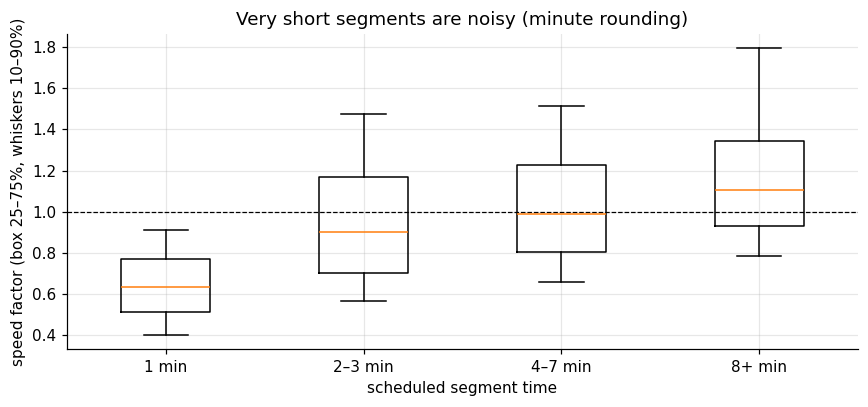

bucket,segments,share_of_time,median_factor,p10,p90
str,u32,f64,f64,f64,f64
"""1 min""",219928,0.020,0.632,0.400,0.909
"""2–3 min""",1238438,0.288,0.902,0.562,1.475
"""4–7 min""",1383867,0.614,0.988,0.659,1.515
"""8+ min""",97735,0.077,1.103,0.783,1.794


In [12]:
bucket = (pl.when(pl.col("sched") < 120).then(pl.lit("1 min"))
            .when(pl.col("sched") < 240).then(pl.lit("2–3 min"))
            .when(pl.col("sched") < 480).then(pl.lit("4–7 min")).otherwise(pl.lit("8+ min")))
b = seg.filter((pl.col("year") == 2024) & ~pl.col("is_last")).with_columns(bucket=bucket)
order = ["1 min", "2–3 min", "4–7 min", "8+ min"]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.boxplot([b.filter(pl.col("bucket") == k)["factor"].to_numpy() for k in order], showfliers=False, whis=(10, 90))
ax.set_xticks(range(1, 5), order); ax.axhline(1, color="k", lw=.8, ls="--")
ax.set_xlabel("scheduled segment time"); ax.set_ylabel("speed factor (box 25–75%, whiskers 10–90%)")
ax.set_title("Very short segments are noisy (minute rounding)")
plt.tight_layout(); savefig(fig, "08_rounding"); plt.show()
(b.group_by("bucket").agg(segments=pl.len(), share_of_time=pl.col("sched").sum(), median_factor=pl.col("factor").median(),
                          p10=pl.col("factor").quantile(.1), p90=pl.col("factor").quantile(.9))
  .with_columns(share_of_time=pl.col("share_of_time") / pl.col("share_of_time").sum()).sort("bucket"))

## 9. Can the past predict the future better than the timetable?
The decisive test. Learn simple lookups on earlier years, score them on a later year they never saw.
Error = mean absolute difference between predicted and actual segment time (seconds), all segments.

| Method | Prediction for a segment trip |
|---|---|
| **B0 timetable** | the scheduled time — what gtfs2emis uses |
| **B1 ratio** | scheduled time ÷ historical median *speed factor* for that segment, day type and hour |
| **B1 time** | historical median *actual time* for that segment, day type and hour (ignores the timetable) |
| **Ceiling** | median actual time per segment, day type and hour **of the test year itself** — the best any such lookup could do (not a real prediction) |

Keys with fewer than 20 training trips fall back to the timetable.

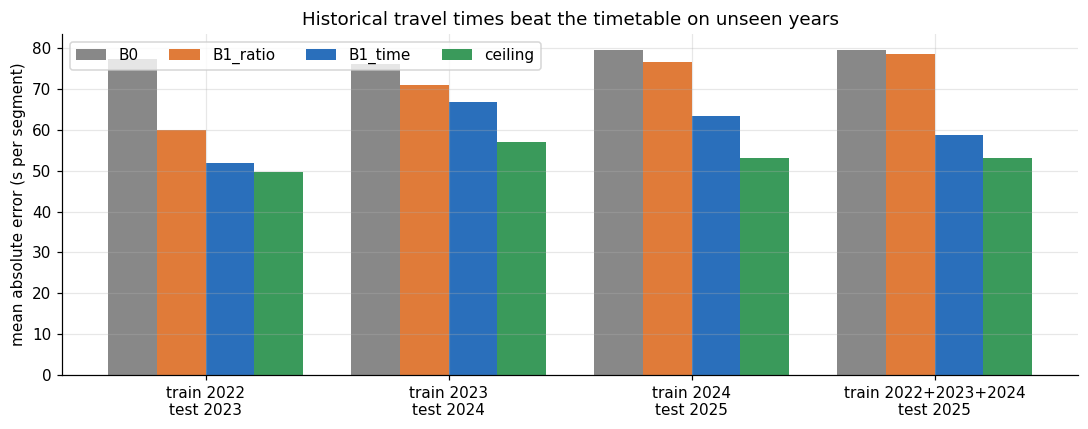

train,test,segments,key_found,B0,B1_ratio,B1_time,ceiling,B1_ratio_vs_B0,B1_time_vs_B0,ceiling_vs_B0
str,i32,u32,f64,f64,f64,f64,f64,f64,f64,f64
"""2022""",2023,3195799,0.999,77.433,59.959,51.959,49.640,0.226,0.329,0.359
"""2023""",2024,3267415,0.923,76.114,71.064,66.933,57.083,0.066,0.121,0.250
"""2024""",2025,3303869,0.998,79.505,76.666,63.533,53.063,0.036,0.201,0.333
"""2022+2023+2024""",2025,3303869,0.998,79.505,78.736,58.758,53.063,0.010,0.261,0.333


In [13]:
KEY = ["route_id", "direction_id", "from_tp", "to_tp", "day_type", "hour"]

def backtest(train_years, test_year, by_route=False):
    tr = seg.filter(pl.col("year").is_in(train_years))
    te = seg.filter(pl.col("year") == test_year)
    tab = (tr.group_by(KEY).agg(f_med=pl.col("factor").median(), t_med=pl.col("act").median(), n=pl.len())
             .filter(pl.col("n") >= 20))
    j = (te.join(tab, on=KEY, how="left")
           .with_columns(B0=pl.col("sched").cast(pl.Float64),
                         B1_ratio=pl.when(pl.col("f_med").is_not_null()).then(pl.col("sched") / pl.col("f_med"))
                                    .otherwise(pl.col("sched")),
                         B1_time=pl.coalesce(pl.col("t_med"), pl.col("sched")),
                         ceiling=pl.col("act").median().over(KEY)))
    grp = ["route_id"] if by_route else []
    err = lambda c: (pl.col(c) - pl.col("act")).abs().mean()
    return (j.group_by(grp or pl.lit(1)).agg(segments=pl.len(), key_found=pl.col("t_med").is_not_null().mean(),
                                             B0=err("B0"), B1_ratio=err("B1_ratio"), B1_time=err("B1_time"),
                                             ceiling=err("ceiling"))
             .with_columns(train=pl.lit("+".join(map(str, train_years))), test=pl.lit(test_year))
             .drop("literal", strict=False))

bt = pl.concat([backtest([2022], 2023), backtest([2023], 2024), backtest([2024], 2025), backtest([2022, 2023, 2024], 2025)])
bt = bt.select("train", "test", "segments", "key_found", "B0", "B1_ratio", "B1_time", "ceiling")
fig, ax = plt.subplots(figsize=(10, 4))
w = .2
for k, (col, color) in enumerate([("B0", "#888"), ("B1_ratio", "#e07b39"), ("B1_time", "#2a6fbb"), ("ceiling", "#3a9a5b")]):
    ax.bar([i + (k - 1.5) * w for i in range(bt.height)], bt[col], w, label=col, color=color)
ax.set_xticks(range(bt.height), [f"train {a}\ntest {b}" for a, b in zip(bt["train"], bt["test"])])
ax.set_ylabel("mean absolute error (s per segment)"); ax.legend(ncol=4)
ax.set_title("Historical travel times beat the timetable on unseen years")
plt.tight_layout(); savefig(fig, "09_backtest"); plt.show()
bt.with_columns((1 - pl.col(c) / pl.col("B0")).alias(f"{c}_vs_B0") for c in ["B1_ratio", "B1_time", "ceiling"])

In [14]:
print("Per route, train 2023 -> test 2024")
br = backtest([2023], 2024, by_route=True).sort("route_id")
br.select("route_id", "segments", "B0", "B1_ratio", "B1_time", "ceiling",
          B1_time_vs_B0=1 - pl.col("B1_time") / pl.col("B0"))

Per route, train 2023 -> test 2024


route_id,segments,B0,B1_ratio,B1_time,ceiling,B1_time_vs_B0
cat,u32,f64,f64,f64,f64,f64
"""01""",471719,81.006,79.828,76.418,65.845,0.057
"""111""",1082695,62.978,50.608,47.410,41.741,0.247
"""28""",637450,77.111,70.224,68.941,58.891,0.106
"""39""",544347,68.459,61.719,62.478,52.618,0.087
"""66""",531204,105.190,115.559,100.453,82.975,0.045


## 10. Conclusions for AI 1
Read together with the numbers above:

1. **The timetable is wrong in two opposite directions.** Mid-route segments are driven slower than scheduled;
   the last segment of each trip contains padding and is driven much faster than scheduled — on some routes the
   timetable implies walking pace there (part 3b). Averaged together they cancel out, which is why route-level
   averages look close to 1 (parts 3–4).
2. **The differences are systematic.** Many segments are consistently slower or faster than the timetable (part 5),
   peaks are slower than midday (part 6), and a simple lookup of past travel times beats the timetable on later,
   unseen years (part 9).
3. **Predict actual travel time / speed, not the ratio to the timetable.** MBTA revises timetables several times a
   year (part 7); each revision shifts the ratio even when buses drive the same. The ratio lookup barely beats the
   timetable on 2025, while the travel-time lookup keeps working (part 9).
4. **Treat the last segment separately** (feature `is_last`, or remove the padding), and give little weight to
   1-minute segments (part 8).
5. **There is a ceiling for lookups** (part 9). To go beyond it, AI 1 needs information a lookup does not have:
   weather, recent behaviour, holidays and school terms. Part of the trip-to-trip variation is pure chance, which
   AI 1 expresses as a 10th–90th percentile range.
6. **For emissions:** gtfs2emis takes speeds from the same padded timetable, so it likely assumes buses are faster
   than reality mid-route and much slower on the last segment. The effect on emission totals is measured in
   Phase 3.1.

*Limits:* five routes; errors are in seconds of travel time and speeds use straight-line distances (road distances
from GTFS shapes come in Phase 1.1); padding is inferred from the data (implausibly slow timetable speeds on the last
segment) and not confirmed by MBTA.